# LAI dataset preparation

This notebook prepares the LAI estimation dataset from the public Mendeley dataset using the actual numerical measurements and the raw image files.

Important notes:
- No synthetic or estimated LAI labels are created.
- The dataset includes both indoor and outdoor image records that are handled explicitly.
- Invalid rows are reported before final filtering.
- The notebook keeps the implementation simple and focused on real LAI values.

In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## 1) Project-relative paths

The notebook uses project-relative paths so it does not depend on absolute machine-specific locations.

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
for candidate in [PROJECT_ROOT, PROJECT_ROOT.parent]:
    if (candidate / 'notebooks').exists() and (candidate / 'README.md').exists():
        PROJECT_ROOT = candidate
        break

DATASET_ROOT = (PROJECT_ROOT.parent / 'DatasetLAI').resolve()
if not DATASET_ROOT.exists():
    DATASET_ROOT = (PROJECT_ROOT / 'DatasetLAI').resolve()

DATA_ROOT = PROJECT_ROOT / 'data'
RESULTS_DIR = PROJECT_ROOT / 'results'
DATA_ROOT.mkdir(exist_ok=True, parents=True)
RESULTS_DIR.mkdir(exist_ok=True, parents=True)

NUMERICAL_DIR = DATASET_ROOT / 'Numerical Data'
RAW_IMAGES_ROOT = DATASET_ROOT / 'Raw Images'

print(f'PROJECT_ROOT: {PROJECT_ROOT}')
print(f'DATASET_ROOT: {DATASET_ROOT}')
print(f'NUMERICAL_DIR exists: {NUMERICAL_DIR.exists()}')
print(f'RAW_IMAGES_ROOT exists: {RAW_IMAGES_ROOT.exists()}')

PROJECT_ROOT: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
DATASET_ROOT: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\DatasetLAI
NUMERICAL_DIR exists: True
RAW_IMAGES_ROOT exists: True


In [3]:
excel_candidates = sorted(NUMERICAL_DIR.glob('*.xlsx')) + sorted(NUMERICAL_DIR.glob('*.xls'))
excel_candidates = [p for p in excel_candidates if p.is_file()]
print('Available Excel files:')
for p in excel_candidates:
    print(f' - {p.name}')

if not excel_candidates:
    raise FileNotFoundError(f'No Excel file found in {NUMERICAL_DIR}.')

workbook_path = next(
    (p for p in excel_candidates if 'Actual Biophysical Signature Measurement and Extracted Data' in p.name),
    excel_candidates[0],
)
print(f'Chosen workbook: {workbook_path}')

Available Excel files:
 - Actual Biophysical Signature Measurement and Extracted Data.xlsx
Chosen workbook: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\DatasetLAI\Numerical Data\Actual Biophysical Signature Measurement and Extracted Data.xlsx


## 2) Inspect the workbook and identify the real measurement sheet

We inspect the workbook first to identify which sheet contains the real image-linked biophysical measurements.

In [5]:
workbook = pd.ExcelFile(workbook_path)
print('Sheet names:')
print(workbook.sheet_names)

for sheet_name in workbook.sheet_names:
    df = pd.read_excel(workbook_path, sheet_name=sheet_name)
    print(f'=== SHEET: {sheet_name} ===')
    print(f'Shape: {df.shape}')
    print('Column names:')
    print(list(df.columns[:20]))
    print('First few rows:')
    print(df.head(5).to_string(index=False))
    print('Missing value summary:')
    print(df.isnull().sum().head(15).to_string())

Sheet names:
['groundtruth', 'in1', 'in2', 'in3', 'in4', 'out1', 'out2', 'out3', 'out4', 'stats']
=== SHEET: groundtruth ===
Shape: (170, 27)
Column names:
['Filename', 'Day', 'Responses (Actual Measurement)', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Predictors', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Filename.1', 'Day.1', 'Responses (Actual Measurement).1', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19']
First few rows:
      Filename   Day Responses (Actual Measurement) Unnamed: 3 Unnamed: 4 Unnamed: 5  Unnamed: 6    Predictors Unnamed: 8  Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12 Unnamed: 13      Filename.1 Day.1 Responses (Actual Measurement).1 Unnamed: 17 Unnamed: 18 Unnamed: 19 Unnamed: 20  Predictors.1 Unnamed: 22 Unnamed: 23 Unnamed: 24 Unnamed: 25 Unnamed: 26
           NaN   NaN                            NaN        NaN        NaN        NaN         NaN           NaN        NaN         NaN         NaN        

The workbook contains a `groundtruth` sheet with paired indoor and outdoor records. The image names are stored as `IN_DAGxxxx.jpg` and `OUT_DAGxxxx.jpg`, and both records appear side-by-side in the same row, with the LAI, FreshWeight, Height, NoOfLeaves, and GrowthStage variables associated to each side.

This means the sheet is not a single flat `image / label` table. We must expand it into one row per image before constructing the final LAI dataset.

In [7]:
raw_groundtruth = pd.read_excel(workbook_path, sheet_name='groundtruth', header=1)
print(f'Loaded sheet: groundtruth')
print(f'Shape: {raw_groundtruth.shape}')
print(raw_groundtruth.head(3).to_string(index=False))
print('First row left block:')
print(raw_groundtruth.iloc[0, :15].to_list())
print('First row right block:')
print(raw_groundtruth.iloc[0, 14:29].to_list())

Loaded sheet: groundtruth
Shape: (169, 27)
    Unnamed: 0 Unnamed: 1  Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5  Unnamed: 6    Unnamed: 7 Unnamed: 8  Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12 Unnamed: 13     Unnamed: 14 Unnamed: 15 Unnamed: 16 Unnamed: 17 Unnamed: 18 Unnamed: 19 Unnamed: 20   Unnamed: 21 Unnamed: 22 Unnamed: 23 Unnamed: 24 Unnamed: 25 Unnamed: 26
           NaN        NaN FreshWeight     Height NoOfLeaves        LAI GrowthStage          area   contrast correlation      energy     entropy homogeneity                         NaN         NaN FreshWeight      Height  NoOfLeaves         LAI GrowthStage          area    contrast correlation      energy     entropy homogeneity
IN_DAG0101.jpg      Day 1           0          0          0   0.032273  Vegetative  81343.197147    0.43981    0.942711    0.834343    0.992098    0.642592         NaN OUT_DAG0101.jpg       Day 1           0           0           0    0.028344  Vegetative  71441.480974    0.986076    0.825214    

In [10]:
records = []
for _, row in raw_groundtruth.iterrows():
    for environment, start_idx in [('IN', 0), ('OUT', 14)]:
        image_filename = row.iloc[start_idx]
        if pd.isna(image_filename) or str(image_filename).strip() == '':
            continue

        records.append({
            'image_filename': str(image_filename).strip(),
            'environment': environment,
            'Day': row.iloc[start_idx + 1],
            'FreshWeight': row.iloc[start_idx + 2],
            'Height': row.iloc[start_idx + 3],
            'NoOfLeaves': row.iloc[start_idx + 4],
            'LAI': row.iloc[start_idx + 5],
            'GrowthStage': row.iloc[start_idx + 6],
        })

lai_df = pd.DataFrame(records).copy()
lai_df['image_filename'] = lai_df['image_filename'].astype(str)
lai_df['LAI_numeric'] = pd.to_numeric(lai_df['LAI'], errors='coerce')
lai_df['FreshWeight_num'] = pd.to_numeric(lai_df['FreshWeight'], errors='coerce')
lai_df['Height_num'] = pd.to_numeric(lai_df['Height'], errors='coerce')
lai_df['NoOfLeaves_num'] = pd.to_numeric(lai_df['NoOfLeaves'], errors='coerce')

print(f'Total raw rows created: {len(lai_df)}')
print(lai_df.head(8).to_string(index=False))
print(f'Environment counts:{lai_df["environment"].value_counts().to_string()}')
print(f'Missing LAI values: {lai_df["LAI_numeric"].isna().sum()}')
print(f'Non-numeric LAI values: {lai_df["LAI_numeric"].isna().sum()}')

Total raw rows created: 336
 image_filename environment   Day  FreshWeight  Height  NoOfLeaves      LAI GrowthStage  LAI_numeric  FreshWeight_num  Height_num  NoOfLeaves_num
 IN_DAG0101.jpg          IN Day 1          0.0     0.0           0 0.032273  Vegetative     0.032273              0.0         0.0               0
OUT_DAG0101.jpg         OUT Day 1          0.0     0.0           0 0.028344  Vegetative     0.028344              0.0         0.0               0
 IN_DAG0201.jpg          IN Day 2          0.0     0.0           0 0.036370  Vegetative     0.036370              0.0         0.0               0
OUT_DAG0201.jpg         OUT Day 2          0.0     0.0           0 0.000504  Vegetative     0.000504              0.0         0.0               0
 IN_DAG0301.jpg          IN Day 3          0.5     1.0           2 0.002650  Vegetative     0.002650              0.5         1.0               2
OUT_DAG0301.jpg         OUT Day 3          0.3     1.0           2 0.001093  Vegetative     0.00

## 3) Validate images and report all invalid rows before removing anything

We resolve each image to its actual corresponding file under the raw image folders, then check for missing files, missing LAI, duplicates, and invalid values. These checks are reported before the final clean dataset is created.

In [12]:
lai_df['image_base'] = lai_df['image_filename'].str.replace(r'^(IN_|OUT_)', '', regex=True)
lai_df['environment_dir'] = np.where(lai_df['environment'] == 'IN', 'Indoor', 'Outdoor')
lai_df['absolute_image_path'] = lai_df.apply(
    lambda row: (RAW_IMAGES_ROOT / row['environment_dir'] / row['image_base']).resolve(),
    axis=1,
)
lai_df['image_exists'] = lai_df['absolute_image_path'].map(lambda p: p.exists())
lai_df['image_path'] = lai_df['absolute_image_path'].apply(lambda p: os.path.relpath(p, PROJECT_ROOT).replace('\\\\', '/')
)

missing_image_mask = ~lai_df['image_exists']
missing_lai_mask = lai_df['LAI_numeric'].isna()
duplicate_image_mask = lai_df['image_filename'].duplicated(keep=False)
duplicate_path_mask = lai_df['image_path'].duplicated(keep=False)
invalid_lai_mask = lai_df['LAI_numeric'].isna()

print('Rows missing image files:', int(missing_image_mask.sum()))
print('Rows missing LAI:', int(missing_lai_mask.sum()))
print('Duplicate image records:', int(duplicate_image_mask.sum()))
print('Duplicate image paths:', int(duplicate_path_mask.sum()))
print('Invalid / non-numeric LAI values:', int(invalid_lai_mask.sum()))

if missing_image_mask.any():
    print('\nMissing image files:')
    print(lai_df.loc[missing_image_mask, ['image_filename', 'environment', 'image_path']].head(20).to_string(index=False))

if missing_lai_mask.any():
    print('\nRows with missing LAI:')
    print(lai_df.loc[missing_lai_mask, ['image_filename', 'environment', 'LAI']].head(20).to_string(index=False))

if duplicate_image_mask.any():
    print('\nDuplicate image records:')
    print(lai_df.loc[duplicate_image_mask, ['image_filename', 'environment', 'image_path']].sort_values('image_filename').head(20).to_string(index=False))

Rows missing image files: 0
Rows missing LAI: 0
Duplicate image records: 0
Duplicate image paths: 0
Invalid / non-numeric LAI values: 0


In [13]:
validity_reasons = {
    'missing_image': ~lai_df['image_exists'],
    'missing_lai': lai_df['LAI_numeric'].isna(),
    'invalid_lai': lai_df['LAI_numeric'].isna(),
    'duplicate_image_record': lai_df['image_filename'].duplicated(keep=False),
    'duplicate_image_path': lai_df['image_path'].duplicated(keep=False),
}

lai_df['removal_reasons'] = ''
for reason, mask in validity_reasons.items():
    lai_df.loc[mask, 'removal_reasons'] = lai_df.loc[mask, 'removal_reasons'].apply(
        lambda current: current + ('; ' if current else '') + reason
    )

remove_mask = lai_df['removal_reasons'].ne('')
removed_rows = lai_df.loc[remove_mask].copy()
print(f'\nRows removed before final filtering: {int(remove_mask.sum())}')
if not removed_rows.empty:
    print('Removed reason counts:')
    removed_counts = removed_rows['removal_reasons'].str.split(';').explode().str.strip().value_counts()
    print(removed_counts.to_string())

final_df = lai_df.loc[~remove_mask].copy().reset_index(drop=True)
final_df['FreshWeight'] = pd.to_numeric(final_df['FreshWeight'], errors='coerce')
final_df['Height'] = pd.to_numeric(final_df['Height'], errors='coerce')
final_df['NoOfLeaves'] = pd.to_numeric(final_df['NoOfLeaves'], errors='coerce')
final_df['LAI'] = pd.to_numeric(final_df['LAI'], errors='coerce')

print(f'Final valid image-LAI pairs before split: {len(final_df)}')
print(final_df.head(5).to_string(index=False))


Rows removed before final filtering: 0
Final valid image-LAI pairs before split: 336
 image_filename environment   Day  FreshWeight  Height  NoOfLeaves      LAI GrowthStage  LAI_numeric  FreshWeight_num  Height_num  NoOfLeaves_num  image_base environment_dir                                                                       absolute_image_path  image_exists                                   image_path removal_reasons
 IN_DAG0101.jpg          IN Day 1          0.0     0.0           0 0.032273  Vegetative     0.032273              0.0         0.0               0 DAG0101.jpg          Indoor  C:\Users\nihar\OneDrive\Desktop\Water To Pixels\DatasetLAI\Raw Images\Indoor\DAG0101.jpg          True  ..\DatasetLAI\Raw Images\Indoor\DAG0101.jpg                
OUT_DAG0101.jpg         OUT Day 1          0.0     0.0           0 0.028344  Vegetative     0.028344              0.0         0.0               0 DAG0101.jpg         Outdoor C:\Users\nihar\OneDrive\Desktop\Water To Pixels\DatasetLAI\Raw

## 4) Split strategy and grouping rationale

The metadata includes a natural grouping identifier in the filename itself, such as `DAG0101`, which corresponds to the same plant/sample across indoor and outdoor measurements. To avoid data leakage, the split should be performed at the plant/sample level rather than on individual rows. If a reliable grouping variable were not available, a reproducible stratified/random split would be the fallback option.

This notebook uses a 70/15/15 split with a fixed random seed.

In [14]:
RANDOM_SEED = 42
final_df['sample_group'] = final_df['image_filename'].str.replace(r'^(IN_|OUT_)', '', regex=True)
final_df['sample_group'] = final_df['sample_group'].str.replace(r'\.jpg$', '', regex=True, case=False)

unique_groups = final_df['sample_group'].drop_duplicates().tolist()
train_groups, temp_groups = train_test_split(
    unique_groups,
    test_size=0.30,
    random_state=RANDOM_SEED,
    shuffle=True,
)
val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=RANDOM_SEED,
    shuffle=True,
)

train_df = final_df[final_df['sample_group'].isin(train_groups)].copy().reset_index(drop=True)
val_df = final_df[final_df['sample_group'].isin(val_groups)].copy().reset_index(drop=True)
test_df = final_df[final_df['sample_group'].isin(test_groups)].copy().reset_index(drop=True)

print(f'Unique sample groups: {len(unique_groups)}')
print(f'Train groups: {len(train_groups)}')
print(f'Validation groups: {len(val_groups)}')
print(f'Test groups: {len(test_groups)}')
print(f'\nRow counts by split:')
print(f'Train: {len(train_df)}')
print(f'Validation: {len(val_df)}')
print(f'Test: {len(test_df)}')
print(f'Total split rows: {len(train_df) + len(val_df) + len(test_df)}')

Unique sample groups: 168
Train groups: 117
Validation groups: 25
Test groups: 26

Row counts by split:
Train: 234
Validation: 50
Test: 52
Total split rows: 336


In [15]:
manifest_columns = [
    'image_filename',
    'image_path',
    'environment',
    'LAI',
    'FreshWeight',
    'Height',
    'NoOfLeaves',
    'GrowthStage',
]

for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_df = split_df[manifest_columns].copy()
    split_df.to_csv(DATA_ROOT / f'lai_{split_name}.csv', index=False)
    print(f'Saved {DATA_ROOT / f"lai_{split_name}.csv"}')

final_df[manifest_columns].to_csv(DATA_ROOT / 'lai_dataset.csv', index=False)
print(f'Saved {DATA_ROOT / "lai_dataset.csv"}')

Saved C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\data\lai_train.csv
Saved C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\data\lai_val.csv
Saved C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\data\lai_test.csv
Saved C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\data\lai_dataset.csv


## 5) LAI target analysis

The clean dataset contains only valid image-LAI pairs. We now inspect the distribution and the environmental and biological composition.

Number of valid samples: 336
Minimum LAI: 0.000481
Maximum LAI: 0.129255
Mean LAI: 0.027350
Median LAI: 0.012130
Standard deviation: 0.029146
Quartiles:
0.00    0.000481
0.25    0.003942
0.50    0.012130
0.75    0.050229
1.00    0.129255
Skewness: 1.065169
Histogram saved to: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results\lai_distribution.png


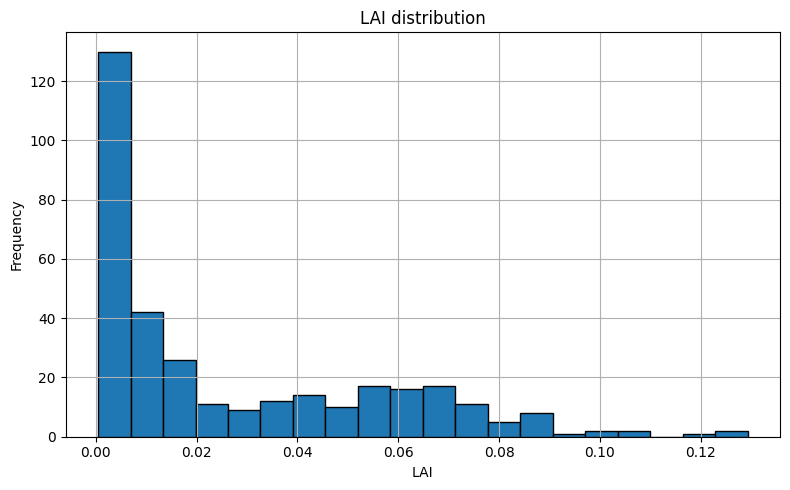

In [20]:
final_df['image_path'] = final_df['absolute_image_path'].apply(
    lambda p: os.path.relpath(p, PROJECT_ROOT).replace('\\', '/')
)

# Summaries for the target variable.
target = final_df['LAI'].dropna().copy()
print(f'Number of valid samples: {len(target)}')
print(f'Minimum LAI: {target.min():.6f}')
print(f'Maximum LAI: {target.max():.6f}')
print(f'Mean LAI: {target.mean():.6f}')
print(f'Median LAI: {target.median():.6f}')
print(f'Standard deviation: {target.std():.6f}')
print('Quartiles:')
print(target.quantile([0.0, 0.25, 0.5, 0.75, 1.0]).to_string())
print(f'Skewness: {target.skew():.6f}')

fig, ax = plt.subplots(figsize=(8, 5))
target.hist(bins=20, ax=ax, edgecolor='black')
ax.set_title('LAI distribution')
ax.set_xlabel('LAI')
ax.set_ylabel('Frequency')
plt.tight_layout()
hist_path = RESULTS_DIR / 'lai_distribution.png'
fig.savefig(hist_path, dpi=150)
print(f'Histogram saved to: {hist_path}')
plt.show()

In [18]:
print('Indoor vs Outdoor counts:')
print(final_df['environment'].value_counts().to_string())
print('\nGrowthStage counts:')
print(final_df['GrowthStage'].value_counts().to_string())

if abs(target.skew()) > 1.0:
    print('The LAI distribution is noticeably skewed based on the absolute skewness value > 1.0.')
else:
    print('The LAI distribution is not heavily skewed based on the absolute skewness value.')

Indoor vs Outdoor counts:
environment
IN     168
OUT    168

GrowthStage counts:
GrowthStage
HeadDevelopment    168
Vegetative         112
Harvest             56
The LAI distribution is noticeably skewed based on the absolute skewness value > 1.0.


In [19]:
summary = {
    'Total valid image-LAI pairs': int(len(final_df)),
    'Training': int(len(train_df)),
    'Validation': int(len(val_df)),
    'Test': int(len(test_df)),
    'Indoor': int((final_df['environment'] == 'IN').sum()),
    'Outdoor': int((final_df['environment'] == 'OUT').sum()),
    'LAI range': f'{target.min():.6f} to {target.max():.6f}',
    'Growth stages': ', '.join(f'{stage}: {count}' for stage, count in final_df['GrowthStage'].value_counts().items()),
}

for key, value in summary.items():
    print(f'{key}: {value}')

Total valid image-LAI pairs: 336
Training: 234
Validation: 50
Test: 52
Indoor: 168
Outdoor: 168
LAI range: 0.000481 to 0.129255
Growth stages: HeadDevelopment: 168, Vegetative: 112, Harvest: 56
